<a href="https://colab.research.google.com/github/esraabanisalman26-ui/CO2_dl_/blob/main/Co2_DL_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [185]:
from google.colab import drive
drive.mount('/content/drive')

import random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/drive/MyDrive/CO2 Emissions_Canada.csv"
TARGET = "CO2 Emissions(g/km)"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [186]:
raw = pd.read_csv(DATA_PATH)
print("raw shape:", raw.shape, "| missing:", int(raw.isna().sum().sum()), "| duplicates:", int(raw.duplicated().sum()))

df = raw.drop_duplicates().reset_index(drop=True)
cols_to_drop = [c for c in df.columns if "Fuel Consumption" in c or c == "Model"]
df = df.drop(columns=cols_to_drop)


print("clean shape:", df.shape)

raw shape: (7385, 12) | missing: 0 | duplicates: 1103
clean shape: (6282, 7)


In [187]:
train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED)  # لا تستخدمه إلا بالآخر

assert len(train_df) + len(val_df) + len(test_df) == len(df)
print("train / val / test:", len(train_df), len(val_df), len(test_df))

train / val / test: 4397 942 943


In [188]:
eda = train_df.copy()
feature_cols = [c for c in eda.columns if c != TARGET]
num_cols = eda[feature_cols].select_dtypes("number").columns.tolist()
cat_cols = eda[feature_cols].select_dtypes(exclude="number").columns.tolist()
print("numeric:", num_cols)
print("categorical:", {c: eda[c].nunique() for c in cat_cols})

numeric: ['Engine Size(L)', 'Cylinders']
categorical: {'Make': 42, 'Vehicle Class': 16, 'Transmission': 27, 'Fuel Type': 4}


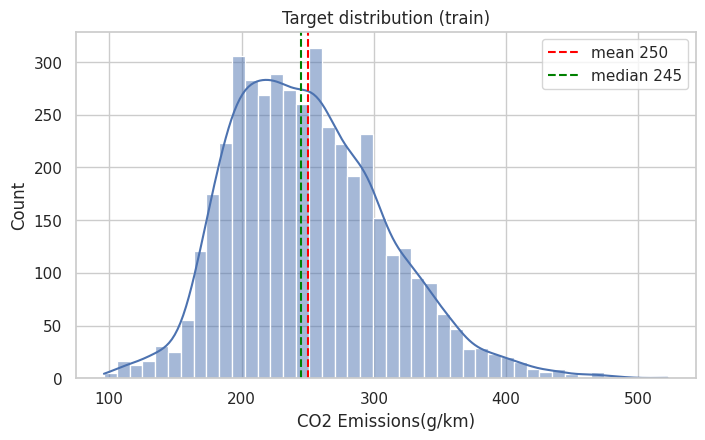

skewness: 0.56


In [189]:
plt.figure(figsize=(8, 4.5))
sns.histplot(eda[TARGET], kde=True)
plt.axvline(eda[TARGET].mean(), color="red", ls="--", label=f"mean {eda[TARGET].mean():.0f}")
plt.axvline(eda[TARGET].median(), color="green", ls="--", label=f"median {eda[TARGET].median():.0f}")
plt.title("Target distribution (train)"); plt.legend(); plt.show()
print("skewness:", round(eda[TARGET].skew(), 2))

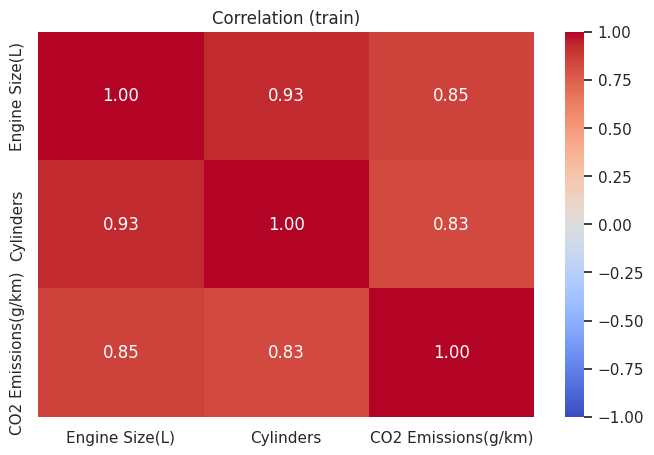

In [190]:
plt.figure(figsize=(8, 5))
sns.heatmap(eda[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation (train)"); plt.show()

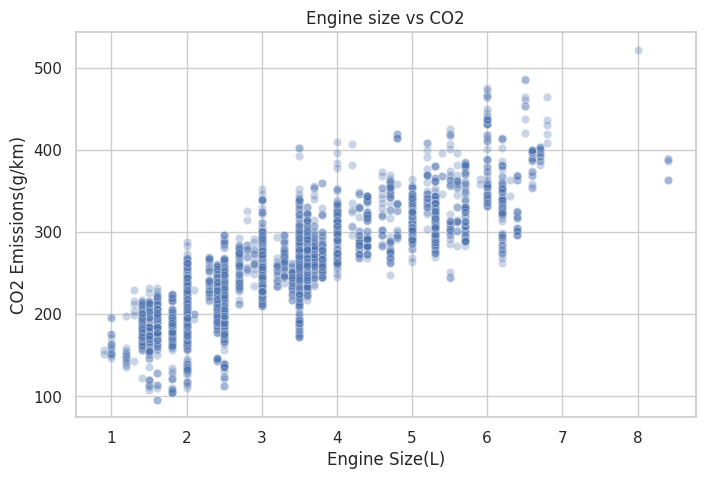

In [191]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=eda, x="Engine Size(L)", y=TARGET, alpha=0.3)
plt.title("Engine size vs CO2"); plt.show()

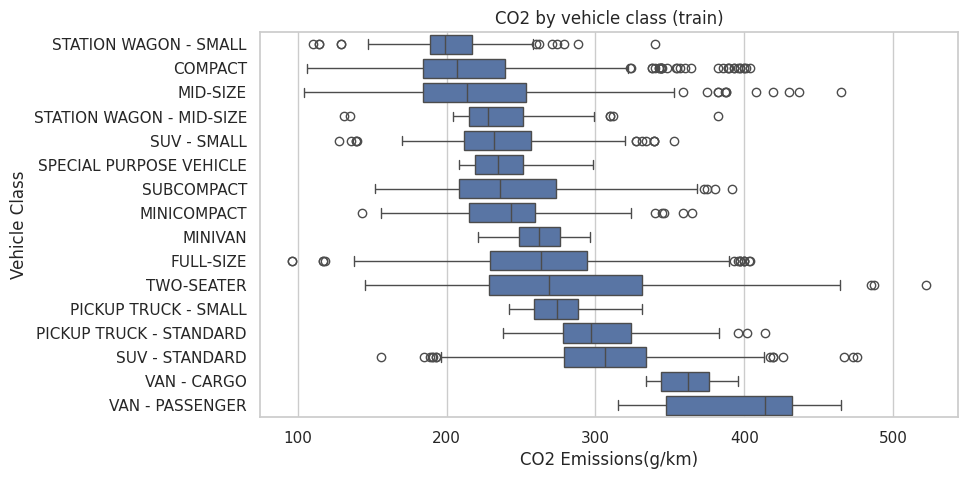

In [192]:
order = eda.groupby("Vehicle Class")[TARGET].median().sort_values().index
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x=TARGET, y="Vehicle Class", order=order)
plt.title("CO2 by vehicle class (train)"); plt.show()

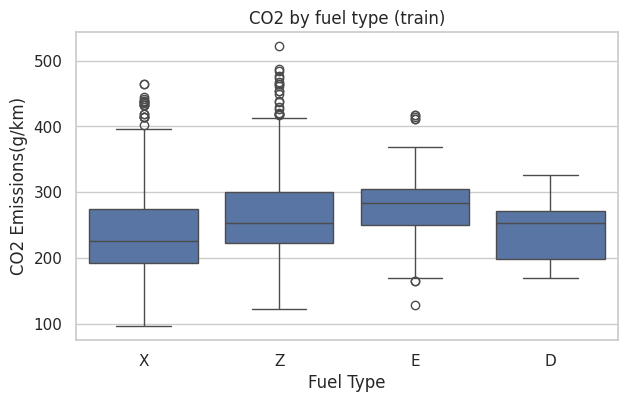

In [193]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=eda, x="Fuel Type", y=TARGET)
plt.title("CO2 by fuel type (train)"); plt.show()

In [194]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr  = pre.fit_transform(train_df[feature_cols]).astype("float32")
X_val = pre.transform(val_df[feature_cols]).astype("float32")
X_te  = pre.transform(test_df[feature_cols]).astype("float32")

y_scaler = StandardScaler().fit(train_df[[TARGET]])
y_tr  = y_scaler.transform(train_df[[TARGET]]).ravel().astype("float32")
y_val = y_scaler.transform(val_df[[TARGET]]).ravel().astype("float32")
y_te  = y_scaler.transform(test_df[[TARGET]]).ravel().astype("float32")
STD = float(y_scaler.scale_[0])

print("features:", X_tr.shape[1], "| shapes:", X_tr.shape, X_val.shape, X_te.shape)

features: 91 | shapes: (4397, 91) (942, 91) (943, 91)


In [195]:
t0 = time.time()
lin = LinearRegression().fit(X_tr, y_tr)
lin_time = time.time() - t0

# Predictions in scaled units
lin_train_pred = lin.predict(X_tr)
lin_val_pred = lin.predict(X_val)

# Convert predictions back to original CO2 units
lin_train_pred = y_scaler.inverse_transform(
    lin_train_pred.reshape(-1, 1)
).ravel()

lin_val_pred = y_scaler.inverse_transform(
    lin_val_pred.reshape(-1, 1)
).ravel()

# Calculate MSE in original units
lin_train = float(
    ((lin_train_pred - train_df[TARGET].values) ** 2).mean()
)

lin_val = float(
    ((lin_val_pred - val_df[TARGET].values) ** 2).mean()
)

print(f"Linear regression | train MSE: {lin_train:.1f} | val MSE: {lin_val:.1f} | time: {lin_time:.2f}s")

LIN_VAL = lin_val

# Largest 10 coefficients
coefs = pd.Series(lin.coef_, index=pre.get_feature_names_out())
print(coefs.sort_values(key=abs, ascending=False).head(10).round(3))

Linear regression | train MSE: 396.0 | val MSE: 440.7 | time: 0.35s
cat__Vehicle Class_VAN - PASSENGER    1.529
cat__Make_BUGATTI                     1.361
cat__Vehicle Class_VAN - CARGO        1.058
cat__Make_LAMBORGHINI                 0.751
cat__Make_MASERATI                    0.735
cat__Transmission_AV6                -0.680
cat__Vehicle Class_MINICOMPACT       -0.624
cat__Make_ACURA                      -0.621
cat__Make_BENTLEY                     0.595
cat__Transmission_AM9                 0.579
dtype: float32


In [196]:
X_train_tensor = torch.tensor(X_tr, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)

y_train_tensor = torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_te, dtype=torch.float32)
y_test_tensor = torch.tensor(y_te, dtype=torch.float32).reshape(-1, 1)

Epoch [1/100], Train MSE: 0.3316, Val MSE: 0.1698
Epoch [2/100], Train MSE: 0.1449, Val MSE: 0.1349
Epoch [3/100], Train MSE: 0.1270, Val MSE: 0.1109
Epoch [4/100], Train MSE: 0.0965, Val MSE: 0.1064
Epoch [5/100], Train MSE: 0.0970, Val MSE: 0.0948
Epoch [6/100], Train MSE: 0.0903, Val MSE: 0.1050
Epoch [7/100], Train MSE: 0.0828, Val MSE: 0.0832
Epoch [8/100], Train MSE: 0.0791, Val MSE: 0.0784
Epoch [9/100], Train MSE: 0.0762, Val MSE: 0.0938
Epoch [10/100], Train MSE: 0.0761, Val MSE: 0.0791
Epoch [11/100], Train MSE: 0.0677, Val MSE: 0.0831
Epoch [12/100], Train MSE: 0.0670, Val MSE: 0.0758
Epoch [13/100], Train MSE: 0.0712, Val MSE: 0.0855
Epoch [14/100], Train MSE: 0.0683, Val MSE: 0.0711
Epoch [15/100], Train MSE: 0.0656, Val MSE: 0.0777
Epoch [16/100], Train MSE: 0.0616, Val MSE: 0.0671
Epoch [17/100], Train MSE: 0.0656, Val MSE: 0.0680
Epoch [18/100], Train MSE: 0.0594, Val MSE: 0.0744
Epoch [19/100], Train MSE: 0.0577, Val MSE: 0.0743
Epoch [20/100], Train MSE: 0.0605, Val M

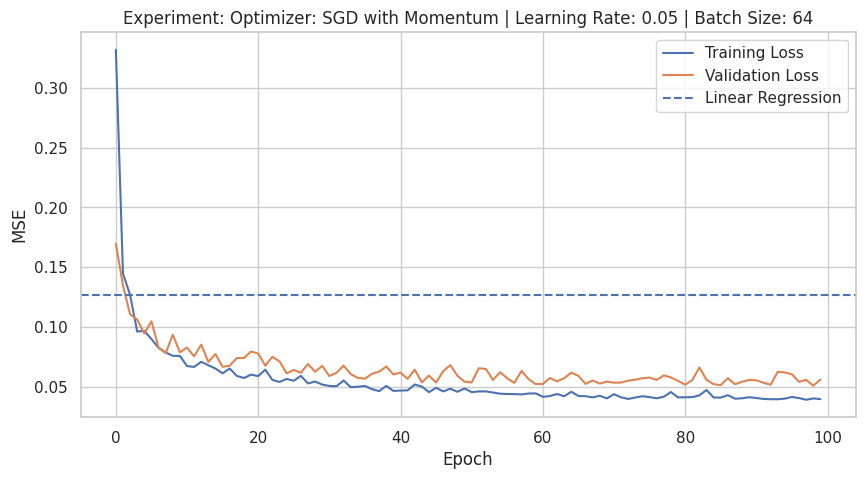

In [197]:
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
# 1. Create Dataset and DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# 2. Build Model
model = nn.Sequential(
    nn.Linear(X_tr.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

# 3. Loss and Optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05,
    momentum=0.9
)

# 4. Training
train_losses = []
val_losses = []

best_val_mse = float("inf")
best_epoch = 0

for epoch in range(100):

    model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        optimizer.zero_grad()

        y_pred = model(batch_X)

        loss = criterion(y_pred, batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * len(batch_X)

    train_mse = total_loss / len(train_dataset)
    train_losses.append(train_mse)

    # Validation
    model.eval()

    with torch.no_grad():
        val_pred = model(X_val_tensor)
        val_loss = criterion(val_pred, y_val_tensor)

    val_losses.append(val_loss.item())

    # Save Best Model
    if val_loss.item() < best_val_mse:
        best_val_mse = val_loss.item()
        best_epoch = epoch + 1

        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch [{epoch+1}/100], "
          f"Train MSE: {train_mse:.4f}, "
          f"Val MSE: {val_loss.item():.4f}")


# 5. Load Best Model
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

print("Best Validation MSE:", best_val_mse)
print("Best Epoch:", best_epoch)


# 6. Plot Loss
experiment_name = (
    f"Optimizer: SGD with Momentum | "
    f"Learning Rate: 0.05 | Batch Size: 64"
)

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.axhline(
    y=LIN_VAL / (STD ** 2),
    linestyle="--",
    label="Linear Regression"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"Experiment: {experiment_name}")
plt.legend()
plt.grid(True)
plt.show()


In [198]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Final Test Evaluation
model.eval()

with torch.no_grad():
    y_pred = model(X_test_tensor).numpy()

y_true = y_test_tensor.numpy()

# Return to original CO2 scale
y_pred = y_scaler.inverse_transform(y_pred)
y_true = y_scaler.inverse_transform(y_true)

print("Final Test Results")
print("------------------")
print("Test MSE:", mean_squared_error(y_true, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
print("Test MAE:", mean_absolute_error(y_true, y_pred))
print("Test R2:", r2_score(y_true, y_pred))

Final Test Results
------------------
Test MSE: 197.0507354736328
Test RMSE: 14.037476107678076
Test MAE: 10.23369312286377
Test R2: 0.9495556950569153


In [199]:
lin_pred = lin.predict(X_te)

lin_pred = y_scaler.inverse_transform(
    lin_pred.reshape(-1, 1)
).ravel()

print("Test MSE:", mean_squared_error(test_df[TARGET], lin_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(test_df[TARGET], lin_pred)))
print("Test MAE:", mean_absolute_error(test_df[TARGET], lin_pred))
print("Test R2:", r2_score(test_df[TARGET], lin_pred))

Test MSE: 369.4093322753906
Test RMSE: 19.22002425272639
Test MAE: 14.775635719299316
Test R2: 0.9054325222969055


In [200]:
import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# تأكدي إن الداتا Tensors جاهزة
X_train_tensor = torch.tensor(X_tr, dtype=torch.float32)
y_train_tensor = torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

results_table = []

def run_experiment(run_id, topic, setting_desc, hidden_layers=[64, 32], lr=0.01,
                   opt_name="Adam", batch_size=100, loss_name="MSE", epochs=100):

    torch.manual_seed(42)
    train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor),
                              batch_size=batch_size, shuffle=True)

    # بناء الشبكة
    layers = []
    in_dim = X_train_tensor.shape[1]
    for h in hidden_layers:
        layers.append(nn.Linear(in_dim, h))
        layers.append(nn.ReLU())
        in_dim = h
    layers.append(nn.Linear(in_dim, 1))
    model = nn.Sequential(*layers)

    # Optimizer
    if opt_name == "Adam": optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "SGD": optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    elif opt_name == "SGD+Momentum": optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    # Loss Function (هنا التعديل المهم)
    if loss_name == "MSE": criterion = nn.MSELoss()
    elif loss_name == "L1": criterion = nn.L1Loss()
    elif loss_name == "Huber": criterion = nn.HuberLoss()

    t0 = time.time()
    train_losses, val_losses = [], []
    best_val_mse = float('inf')
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(bx)

        train_mse_scaled = total_loss / len(train_loader.dataset)
        train_losses.append(train_mse_scaled)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_tensor), y_val_tensor).item()
            val_losses.append(val_loss)
            if val_loss < best_val_mse:
                best_val_mse = val_loss
                best_epoch = epoch + 1

    elapsed = time.time() - t0

    results_table.append({
        "Topic": topic, "Configuration": setting_desc,
        "Val. MSE": round(best_val_mse, 6) if not np.isnan(best_val_mse) else "nan",
        "Train. MSE": round(train_losses[-1], 6),
        "Epoch": best_epoch, "Time (s)": round(elapsed, 1)
    })
    print(f"✅ {topic} | {setting_desc} -> Val MSE: {best_val_mse:.6f} | Time: {elapsed:.1f}s")


In [201]:
# --- 1. Learning Rate (5 تجارب) ---
run_experiment(1, "Learning rate", "0.1", lr=0.1, opt_name="Adam")
run_experiment(2, "Learning rate", "0.01", lr=0.01, opt_name="Adam") # Baseline
run_experiment(3, "Learning rate", "0.001", lr=0.001, opt_name="Adam")
run_experiment(4, "Learning rate", "0.0001", lr=0.0001, opt_name="Adam")
run_experiment(5, "Learning rate", "0.005", lr=0.005, opt_name="Adam")

# --- 2. Optimizer (2 تجارب) ---
run_experiment(6, "Optimizer", "SGD; LR 0.01", lr=0.01, opt_name="SGD")
run_experiment(7, "Optimizer", "SGD+Momentum; LR 0.01", lr=0.01, opt_name="SGD+Momentum")

# --- 3. Batch Size (5 تجارب) ---
run_experiment(8, "Batch size", "16", batch_size=16, lr=0.01, opt_name="Adam")
run_experiment(9, "Batch size", "32", batch_size=32, lr=0.01, opt_name="Adam")
run_experiment(10, "Batch size", "64", batch_size=64, lr=0.01, opt_name="Adam")
run_experiment(11, "Batch size", "256", batch_size=256, lr=0.01, opt_name="Adam")
run_experiment(12, "Batch size", "512", batch_size=512, lr=0.01, opt_name="Adam")

# --- 4. Architecture (3 تجارب) ---
run_experiment(13, "Architecture", "64-32-16", hidden_layers=[64, 32, 16], lr=0.01, opt_name="Adam", batch_size=100)
run_experiment(14, "Architecture", "128-64", hidden_layers=[128, 64], lr=0.01, opt_name="Adam", batch_size=100)
run_experiment(15, "Architecture", "32-16", hidden_layers=[32, 16], lr=0.01, opt_name="Adam", batch_size=100)


✅ Learning rate | 0.1 -> Val MSE: 0.067627 | Time: 11.4s
✅ Learning rate | 0.01 -> Val MSE: 0.052348 | Time: 8.6s
✅ Learning rate | 0.001 -> Val MSE: 0.054701 | Time: 10.2s
✅ Learning rate | 0.0001 -> Val MSE: 0.077959 | Time: 9.2s
✅ Learning rate | 0.005 -> Val MSE: 0.052537 | Time: 10.7s
✅ Optimizer | SGD; LR 0.01 -> Val MSE: 0.103054 | Time: 8.3s
✅ Optimizer | SGD+Momentum; LR 0.01 -> Val MSE: 0.056065 | Time: 7.0s
✅ Batch size | 16 -> Val MSE: 0.054663 | Time: 41.8s
✅ Batch size | 32 -> Val MSE: 0.050583 | Time: 21.8s
✅ Batch size | 64 -> Val MSE: 0.052650 | Time: 13.3s
✅ Batch size | 256 -> Val MSE: 0.053561 | Time: 6.4s
✅ Batch size | 512 -> Val MSE: 0.051831 | Time: 5.4s
✅ Architecture | 64-32-16 -> Val MSE: 0.054053 | Time: 11.0s
✅ Architecture | 128-64 -> Val MSE: 0.052405 | Time: 10.7s
✅ Architecture | 32-16 -> Val MSE: 0.056922 | Time: 9.9s


In [202]:
df_results = pd.DataFrame(results_table)
display(df_results)

,Topic,Configuration,Val. MSE,Train. MSE,Epoch,Time (s)
0,Learning rate,0.1,0.067627,0.075358,79,11.4
1,Learning rate,0.01,0.052348,0.039474,61,8.6
2,Learning rate,0.001,0.054701,0.042873,97,10.2
3,Learning rate,0.0001,0.077959,0.067680,99,9.2
4,Learning rate,0.005,0.052537,0.039092,92,10.7
5,Optimizer,SGD; LR 0.01,0.103054,0.094078,100,8.3
6,Optimizer,SGD+Momentum; LR 0.01,0.056065,0.046273,100,7.0
7,Batch size,16,0.054663,0.043546,83,41.8
8,Batch size,32,0.050583,0.042676,90,21.8
9,Batch size,64,0.052650,0.041466,47,13.3


In [203]:
#-- تجارب الـ  15 (Loss function & Optimizer+LR & Batch) ---

# Loss Functions
run_experiment(16, "Loss function", "L1", loss_name="L1", lr=0.01, opt_name="Adam")
run_experiment(17, "Loss function", "Huber", loss_name="Huber", lr=0.01, opt_name="Adam")

# Optimizer + LR
run_experiment(18, "Optimizer + LR", "SGD+M LR 0.005", lr=0.005, opt_name="SGD+Momentum")
run_experiment(19, "Optimizer + LR", "SGD+M LR 0.02", lr=0.02, opt_name="SGD+Momentum")
run_experiment(20, "Optimizer + LR", "SGD LR 0.02", lr=0.02, opt_name="SGD")
run_experiment(21, "Optimizer + LR", "Adam LR 0.02", lr=0.02, opt_name="Adam")
run_experiment(22, "Optimizer + LR", "SGD LR 0.005", lr=0.005, opt_name="SGD")
run_experiment(23, "Optimizer + LR", "SGD LR 0.05", lr=0.05, opt_name="SGD")
run_experiment(24, "Optimizer + LR", "SGD+M LR 0.05", lr=0.05, opt_name="SGD+Momentum")
run_experiment(25, "Optimizer + LR", "SGD+M LR 0.1", lr=0.1, opt_name="SGD+Momentum")

# Batch Size with SGD+Momentum
run_experiment(26, "Batch size", "SGD+M Batch 16", batch_size=16, lr=0.05, opt_name="SGD+Momentum")
run_experiment(27, "Batch size", "SGD+M Batch 32", batch_size=32, lr=0.05, opt_name="SGD+Momentum")
run_experiment(28, "Batch size", "SGD+M Batch 64", batch_size=64, lr=0.05, opt_name="SGD+Momentum")
run_experiment(29, "Batch size", "SGD+M Batch 256", batch_size=256, lr=0.05, opt_name="SGD+Momentum")
run_experiment(30, "Batch size", "SGD+M Batch 512", batch_size=512, lr=0.05, opt_name="SGD+Momentum")

✅ Loss function | L1 -> Val MSE: 0.168954 | Time: 10.3s
✅ Loss function | Huber -> Val MSE: 0.027206 | Time: 9.1s
✅ Optimizer + LR | SGD+M LR 0.005 -> Val MSE: 0.064772 | Time: 8.9s
✅ Optimizer + LR | SGD+M LR 0.02 -> Val MSE: 0.055161 | Time: 7.2s
✅ Optimizer + LR | SGD LR 0.02 -> Val MSE: 0.085000 | Time: 8.3s
✅ Optimizer + LR | Adam LR 0.02 -> Val MSE: 0.054895 | Time: 9.1s
✅ Optimizer + LR | SGD LR 0.005 -> Val MSE: 0.138189 | Time: 8.0s
✅ Optimizer + LR | SGD LR 0.05 -> Val MSE: 0.069708 | Time: 6.9s
✅ Optimizer + LR | SGD+M LR 0.05 -> Val MSE: 0.051455 | Time: 8.8s
✅ Optimizer + LR | SGD+M LR 0.1 -> Val MSE: 0.052384 | Time: 7.7s
✅ Batch size | SGD+M Batch 16 -> Val MSE: 0.055800 | Time: 29.9s
✅ Batch size | SGD+M Batch 32 -> Val MSE: 0.050984 | Time: 17.3s
✅ Batch size | SGD+M Batch 64 -> Val MSE: 0.051288 | Time: 10.3s
✅ Batch size | SGD+M Batch 256 -> Val MSE: 0.056076 | Time: 5.8s
✅ Batch size | SGD+M Batch 512 -> Val MSE: 0.059392 | Time: 5.2s


In [204]:
df_results = pd.DataFrame(results_table)
display(df_results)

,Topic,Configuration,Val. MSE,Train. MSE,Epoch,Time (s)
0,Learning rate,0.1,0.067627,0.075358,79,11.4
1,Learning rate,0.01,0.052348,0.039474,61,8.6
2,Learning rate,0.001,0.054701,0.042873,97,10.2
3,Learning rate,0.0001,0.077959,0.067680,99,9.2
4,Learning rate,0.005,0.052537,0.039092,92,10.7
5,Optimizer,SGD; LR 0.01,0.103054,0.094078,100,8.3
6,Optimizer,SGD+Momentum; LR 0.01,0.056065,0.046273,100,7.0
7,Batch size,16,0.054663,0.043546,83,41.8
8,Batch size,32,0.050583,0.042676,90,21.8
9,Batch size,64,0.052650,0.041466,47,13.3


In [205]:
# --- حساب Test MSE لموديل Huber ---
import torch.nn as nn
import torch

# بناء الشبكة
best_model = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1)
)
# اختيار الـ Optimizer والـ Loss اللي طلعوا الأفضل
optimizer = torch.optim.Adam(best_model.parameters(), lr=0.01)
criterion = nn.HuberLoss()

# تدريب سريع (عشان الموديل يتعلم)
best_model.train()
from torch.utils.data import DataLoader, TensorDataset
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=100, shuffle=True)

for epoch in range(100): # 100 دورة كفاية
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(best_model(bx), by)
        loss.backward()
        optimizer.step()

# حساب الـ Test مرة واحدة بس
best_model.eval()
with torch.no_grad():
    test_pred_scaled = best_model(X_test_tensor)
    test_mse_scaled = criterion(test_pred_scaled, y_test_tensor).item()
    test_mse_original = test_mse_scaled * (STD ** 2)

print(f"✅ Final Huber Model Test MSE (Original Scale): {test_mse_original:.2f}")

✅ Final Huber Model Test MSE (Original Scale): 104.42
